In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (accuracy_score, f1_score, mean_squared_error, mean_absolute_error, r2_score)
from sklearn.datasets import load_iris, load_wine, load_breast_cancer, load_diabetes, make_friedman1
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.model_selection import KFold
from itertools import product
from scipy import stats

In [2]:
np.random.seed(123)

In [3]:
# ACTIVATION FUNCTIONS
def tanh(x):
    return np.tanh(x)


def tanh_derivative(x):
    return 1 - np.tanh(x) ** 2

In [4]:
# OUTPUT FUNCTIONS

# REGRSSION
def linear(x):
    return x


def linear_derivative(x):
    return np.ones_like(x)

# BINARY CLASSIFICATION
def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))


def sigmoid_derivative(x):
    s = sigmoid(x)
    return s * (1 - s)

# MULTI-CLASS CLASSIFICATION
def softmax(x):
    x = x - np.max(x, axis=1, keepdims=True)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

In [5]:
# LOSS FUNCTIONS

# REGRESSION
def mse_loss(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

#BINARY CLASSIFICATION
def binary_cross_entropy(y_true, y_pred):
    eps = 1e-12
    y_pred = np.clip(y_pred, eps, 1 - eps)

    return -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )

#MULTICLASS CLASSIFICATION
def categorical_cross_entropy(y_true, y_pred):
    eps = 1e-12
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -np.mean(np.sum(y_true * np.log(y_pred), axis=1))

In [6]:
class NeuralNetwork:

    def __init__(self, input_size, hidden_size, output_size,
                 output_activation="linear", seed=42):

        rng = np.random.default_rng(seed) # RANDOM NUMBER GENERATOR

        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.output_activation = output_activation

        # Xavier-style initialisation
        self.W1 = rng.normal(
            0,
            np.sqrt(1 / input_size),
            size=(input_size, hidden_size)
        )

        self.b1 = np.zeros((1, hidden_size))

        self.W2 = rng.normal(
            0,
            np.sqrt(1 / hidden_size),
            size=(hidden_size, output_size)
        )

        self.b2 = np.zeros((1, output_size))

    def forward(self, X):
        self.z1 = X @ self.W1 + self.b1
        self.a1 = tanh(self.z1)

        self.z2 = self.a1 @ self.W2 + self.b2

        if self.output_activation == "sigmoid":
            self.a2 = sigmoid(self.z2)

        elif self.output_activation == "softmax":
            self.a2 = softmax(self.z2)

        elif self.output_activation == "linear":
            self.a2 = self.z2

        return self.a2

    # BACK PROPAGATION
    def gradients(self, X, y):
        y_pred = self.forward(X)
        n = X.shape[0]

        if self.output_activation == "linear":
            delta2 = (y_pred - y) / n
        elif self.output_activation == "sigmoid":
            # Binary cross-entropy + sigmoid
            delta2 = (y_pred - y) / n
        elif self.output_activation == "softmax":
            # Cross-entropy + softmax
            delta2 = (y_pred - y) / n

        dW2 = self.a1.T @ delta2
        db2 = np.sum(delta2, axis=0, keepdims=True)

        # Hidden layer
        delta1 = (delta2 @ self.W2.T) * tanh_derivative(self.z1)

        dW1 = X.T @ delta1
        db1 = np.sum(delta1, axis=0, keepdims=True)

        return dW1, db1, dW2, db2

    def get_params(self):
        return np.concatenate([self.W1.ravel(), self.b1.ravel(),self.W2.ravel(), self.b2.ravel()])

    def set_params(self, theta):
        i, h, o = self.input_size, self.hidden_size, self.output_size
        idx = 0
        self.W1 = theta[idx: idx + i*h].reshape(i, h); idx += i*h
        self.b1 = theta[idx: idx + h].reshape(1, h);   idx += h
        self.W2 = theta[idx: idx + h*o].reshape(h, o); idx += h*o
        self.b2 = theta[idx: idx + o].reshape(1, o)

In [7]:
def make_objective(network, X, y, loss_function):
        def objective(theta):
            network.set_params(theta)
            y_pred = network.forward(X)
            return loss_function(y, y_pred)
    
        def gradient(theta):
            network.set_params(theta)
            dW1, db1, dW2, db2 = network.gradients(X, y)
            return np.concatenate([dW1.ravel(), db1.ravel(), dW2.ravel(), db2.ravel()])
    
        return objective, gradient

In [8]:
class SGD:

    def __init__(self, learning_rate=0.01):
        self.learning_rate = learning_rate

    def step(self, network, gradients):
        dW1, db1, dW2, db2 = gradients

        network.W1 -= self.learning_rate * dW1
        network.b1 -= self.learning_rate * db1

        network.W2 -= self.learning_rate * dW2
        network.b2 -= self.learning_rate * db2

In [9]:
def train_sgd(network, optimizer, X_train, y_train, epochs=1000, loss_function=mse_loss, shuffle=True):
        history = []
    
        n = X_train.shape[0]
    
        for epoch in range(epochs):
            if shuffle:
                indices = np.random.permutation(n)
            else:
                indices = np.arange(n)
    
            for i in indices:
                X_sample = X_train[i:i+1]
                y_sample = y_train[i:i+1]
    
                gradients = network.gradients(X_sample, y_sample)
    
                optimizer.step(network, gradients)
    
            predictions = network.forward(X_train)
            loss = loss_function(y_train, predictions)
    
            history.append(loss)
    
        return history

In [10]:
def train_scg(theta0, objective, gradient, restart_every=None,
              max_iter=1000, sigma=1e-4, lambda1=1e-6, tol=1e-6,
              val_objective=None, patience=None):
    theta = theta0.copy()
    n = theta.size
    if restart_every is None:
        restart_every = n

    lam, lam_bar = lambda1, 0.0
    r = -gradient(theta)
    p = r.copy()
    success = True
    k = 1
    fval = objective(theta)
    history = [fval]

    best_theta = theta.copy()
    best_val = val_objective(theta) if val_objective else None
    no_improve = 0

    while True:
        if success:
            sigma_k = sigma / np.linalg.norm(p)
            s = (gradient(theta + sigma_k * p) - gradient(theta)) / sigma_k
            delta = p @ s

        delta = delta + (lam - lam_bar) * (p @ p)

        if delta <= 0:
            lam_bar = 2 * (lam - delta / (p @ p))
            delta = -delta + lam * (p @ p)
            lam = lam_bar

        mu = p @ r
        alpha = mu / delta
        f_new = objective(theta + alpha * p)
        Delta = 2 * delta * (fval - f_new) / (mu ** 2)

        if Delta >= 0:
            theta = theta + alpha * p
            r_new = -gradient(theta)
            lam_bar = 0.0
            success = True
            fval = f_new
            history.append(fval)

            if val_objective is not None:
                val_loss = val_objective(theta)
                if val_loss < best_val:
                    best_val, best_theta, no_improve = val_loss, theta.copy(), 0
                else:
                    no_improve += 1
                if patience is not None and no_improve >= patience:
                    break

            if k % restart_every == 0:
                p = r_new.copy()
            else:
                beta = (r_new @ r_new - r_new @ r) / mu
                p = r_new + beta * p
            r = r_new

            if Delta >= 0.75:
                lam = 0.25 * lam
        else:
            lam_bar = lam
            success = False

        if Delta < 0.25:
            lam = lam + delta * (1 - Delta) / (p @ p)

        if np.linalg.norm(r) < tol or k >= max_iter:
            break
        k += 1

    return (best_theta if val_objective is not None else theta), history

In [11]:
def train_leapfrog(theta0, objective, gradient,
                    delta=1.0, delta1=1e-3, m=3, eps=1e-5,
                    dt_init=0.5, dt_max=None, max_iter=2000,
                    val_objective=None, patience=None):
    dt_max = dt_init * 20 if dt_max is None else dt_max
    x = theta0.copy()
    x_prev = x.copy()
    a_prev = -gradient(x)
    v = 0.5 * a_prev * dt_init
    v_prev = v.copy()
    dt = dt_init
    p, s, i, j = 1, 0, 0, 2
    k = -1

    history = [objective(x)]
    best_x = x.copy()
    best_val = val_objective(x) if val_objective else None
    no_improve = 0
    state = 'S3'
    evals = 0

    while state != 'STOP' and evals < max_iter:
        if state == 'S3':
            k += 1
            dx_norm = np.linalg.norm(v) * dt
            state = 'S4'
        elif state == 'S4':
            if dx_norm < delta:
                state = 'S5A'
            else:
                v = delta * v / (dt * np.linalg.norm(v))
                state = 'S5B'
        elif state == 'S5A':
            p = p + delta1
            dt = min(p * dt, dt_max)
            state = 'S5'
        elif state == 'S5B':
            if s < m:
                state = 'S5'
            else:
                dt = dt / 2
                x = (x + x_prev) / 2
                v = (v + v_prev) / 4
                s = 0
                state = 'S5'
        elif state == 'S5':
            x_next = x + v * dt
            x_prev = x
            v_prev = v.copy()
            x = x_next
            state = 'S6'
        elif state == 'S6':
            a_next = -gradient(x)
            v = v + a_next * dt
            evals += 1
            history.append(objective(x))

            if val_objective is not None:
                val_loss = val_objective(x)
                if val_loss < best_val:
                    best_val, best_x, no_improve = val_loss, x.copy(), 0
                else:
                    no_improve += 1
                if patience is not None and no_improve >= patience:
                    state = 'STOP'
                    continue

            state = 'S7A'
        elif state == 'S7A':
            if a_next @ a_prev > 0:
                s = 0
            else:
                s = s + 1
                p = 1
            a_prev = a_next
            state = 'S7'
        elif state == 'S7':
            state = 'STOP' if np.linalg.norm(a_next) <= eps else 'S8'
        elif state == 'S8':
            if np.linalg.norm(v) > np.linalg.norm(v_prev):
                i = 0
                state = 'S3'
            else:
                x = (x + x_prev) / 2
                i = i + 1
                state = 'S9'
        elif state == 'S9':
            if i <= j:
                v = (v + v_prev) / 4
            else:
                v = np.zeros_like(v)
                j = 1
            k += 1
            state = 'S6'

    return (best_x if val_objective is not None else x), history

In [12]:
def train_model(network, X, y, algorithm, loss_function, X_val=None, y_val=None,
                 patience=None, **kwargs):
    if algorithm == 'sgd':
        optimizer = SGD(learning_rate=kwargs.get('learning_rate', 0.01))
        history = train_sgd(network, optimizer, X, y,
                             epochs=kwargs.get('epochs', 200),
                             loss_function=loss_function)
    elif algorithm in ('scg', 'leapfrog'):
        objective, gradient = make_objective(network, X, y, loss_function)
        theta0 = network.get_params()
        val_objective = None
        if X_val is not None:
            val_obj_fn, _ = make_objective(network, X_val, y_val, loss_function)
            val_objective = val_obj_fn
        if algorithm == 'scg':
            theta, history = train_scg(theta0, objective, gradient,
                                        max_iter=kwargs.get('max_iter', 1000),
                                        val_objective=val_objective, patience=patience)
        else:
            theta, history = train_leapfrog(theta0, objective, gradient,
                                             delta=kwargs.get('delta', 0.02),
                                             dt_init=kwargs.get('dt_init', 0.5),
                                             max_iter=kwargs.get('max_iter', 500),
                                             val_objective=val_objective, patience=patience)
        network.set_params(theta)
    else:
        raise ValueError(algorithm)
    return history

In [13]:
def load_regression_datasets():
    X_sine = np.linspace(-3, 3, 400).reshape(-1, 1)
    y_sine = np.sin(X_sine).ravel() + np.random.normal(0, 0.1, X_sine.shape[0])
    X_fr, y_fr = make_friedman1(n_samples=500, n_features=10, noise=1.0, random_state=123)
    return {
        'sine': (X_sine, y_sine),                # simple, 1D
        'diabetes': load_diabetes(return_X_y=True), # medium, 10 features
        'friedman1': (X_fr, y_fr),               # harder, nonlinear interactions
    }

def prep_classification(X, y, test_size=0.3):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size,
                                                          random_state=123, stratify=y)
    scaler = StandardScaler().fit(X_train)
    X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)
    ohe = OneHotEncoder(sparse_output=False).fit(y_train.reshape(-1, 1))
    y_train_enc = ohe.transform(y_train.reshape(-1, 1))
    y_test_enc = ohe.transform(y_test.reshape(-1, 1))
    return X_train, X_test, y_train_enc, y_test_enc

def prep_regression(X, y, test_size=0.3):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=123)
    x_scaler = StandardScaler().fit(X_train)
    y_scaler = StandardScaler().fit(y_train.reshape(-1, 1))
    X_train, X_test = x_scaler.transform(X_train), x_scaler.transform(X_test)
    y_train = y_scaler.transform(y_train.reshape(-1, 1))
    y_test = y_scaler.transform(y_test.reshape(-1, 1))
    return X_train, X_test, y_train, y_test

[iris] sgd      final train loss = 0.00764   test acc = 0.956
[iris] scg      final train loss = 0.00000   test acc = 0.933
[iris] leapfrog final train loss = 0.03038   test acc = 0.933
[sine] sgd      final train loss = 0.02094   test MSE = 0.02856
[sine] scg      final train loss = 0.01658   test MSE = 0.02268
[sine] leapfrog final train loss = 0.01774   test MSE = 0.02380


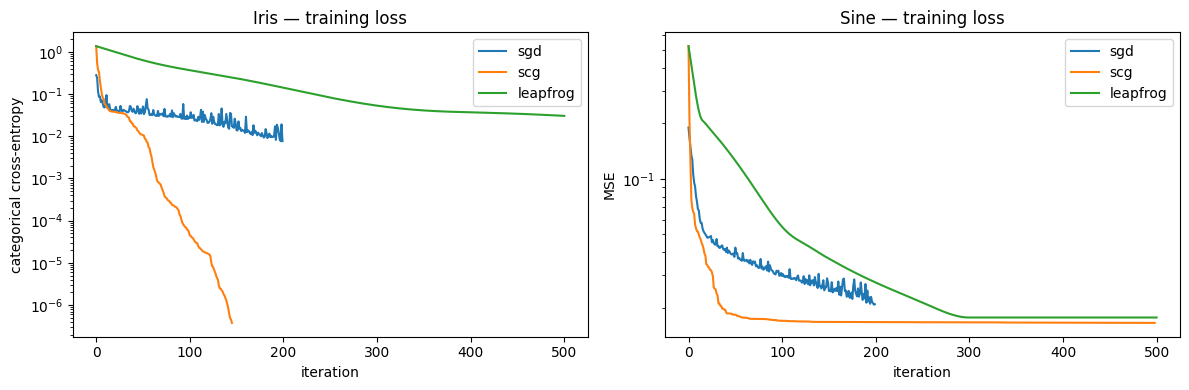

In [23]:
# CLASSIFICATION- IRIS
X_iris, y_iris = load_iris(return_X_y=True)
X_train_c, X_test_c, y_train_c, y_test_c = prep_classification(X_iris, y_iris)

n_features_c = X_train_c.shape[1]
n_classes_c = y_train_c.shape[1]

results_c = {}
for algo in ['sgd', 'scg', 'leapfrog']:
    net = NeuralNetwork(n_features_c, hidden_size=10, output_size=n_classes_c,
                         output_activation='softmax', seed=42)
    kwargs = {'learning_rate': 0.1, 'epochs': 200} if algo == 'sgd' else {'max_iter': 500}
    history = train_model(net, X_train_c, y_train_c, algo,
                           categorical_cross_entropy, **kwargs)
    y_pred_test = net.forward(X_test_c)
    acc = accuracy_score(y_test_c.argmax(axis=1), y_pred_test.argmax(axis=1))
    results_c[algo] = {'history': history, 'test_acc': acc}
    print(f"[iris] {algo:8s} final train loss = {history[-1]:.5f}   test acc = {acc:.3f}")

# REGRESSION- SINE
X_sine, y_sine = load_regression_datasets()['sine']
X_train_r, X_test_r, y_train_r, y_test_r = prep_regression(X_sine, y_sine)

n_features_r = X_train_r.shape[1]

results_r = {}
for algo in ['sgd', 'scg', 'leapfrog']:
    net = NeuralNetwork(n_features_r, hidden_size=10, output_size=1,
                         output_activation='linear', seed=42)
    kwargs = {'learning_rate': 0.01, 'epochs': 200} if algo == 'sgd' else {'max_iter': 500}
    history = train_model(net, X_train_r, y_train_r, algo, mse_loss, **kwargs)
    y_pred_test = net.forward(X_test_r)
    test_mse = mean_squared_error(y_test_r, y_pred_test)
    results_r[algo] = {'history': history, 'test_mse': test_mse}
    print(f"[sine] {algo:8s} final train loss = {history[-1]:.5f}   test MSE = {test_mse:.5f}")

# PLOTS
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for algo in ['sgd', 'scg', 'leapfrog']:
    axes[0].plot(results_c[algo]['history'], label=algo)
axes[0].set_title('Iris — training loss')
axes[0].set_xlabel('iteration')
axes[0].set_ylabel('categorical cross-entropy')
axes[0].set_yscale('log')
axes[0].legend()

for algo in ['sgd', 'scg', 'leapfrog']:
    axes[1].plot(results_r[algo]['history'], label=algo)
axes[1].set_title('Sine — training loss')
axes[1].set_xlabel('iteration')
axes[1].set_ylabel('MSE')
axes[1].set_yscale('log')
axes[1].legend()

plt.tight_layout()
plt.savefig('convergence.png', dpi=200)
plt.show()

In [15]:
def cv_score(algo, X, y, hidden_size, output_size, output_activation,
             loss_function, params, k=5, seed=123, use_early_stopping=True, patience=15):
    kf = KFold(n_splits=k, shuffle=True, random_state=seed)
    scores = []
    for train_idx, val_idx in kf.split(X):
        X_tr, X_val = X[train_idx], X[val_idx]
        y_tr, y_val = y[train_idx], y[val_idx]

        X_fit, X_stop, y_fit, y_stop = None, None, None, None
        if use_early_stopping and algo in ('scg', 'leapfrog'):
            X_fit, X_stop, y_fit, y_stop = train_test_split(X_tr, y_tr, test_size=0.2,
                                                              random_state=seed)
        else:
            X_fit, y_fit = X_tr, y_tr

        net = NeuralNetwork(X.shape[1], hidden_size, output_size,
                             output_activation=output_activation, seed=42)
        train_model(net, X_fit, y_fit, algo, loss_function,
                    X_val=X_stop, y_val=y_stop, patience=patience, **params)
        y_pred = net.forward(X_val)
        scores.append(loss_function(y_val, y_pred))
    return np.mean(scores), np.std(scores)


def search_hidden_units(algo, X, y, output_size, output_activation, loss_function,
                         params, hidden_sizes=(2, 5, 10, 20, 30, 50), k=5):
    results = []
    for h in hidden_sizes:
        mean, std = cv_score(algo, X, y, h, output_size, output_activation,
                              loss_function, params, k=k)
        results.append((h, mean, std))
        print(f"hidden={h:3d}  val_loss={mean:.5f} ± {std:.5f}")
    return sorted(results, key=lambda r: r[1])


def search_hyperparams(algo, X, y, hidden_size, output_size, output_activation,
                        loss_function, param_grid, k=5):
    keys = list(param_grid.keys())
    results = []
    for values in product(*param_grid.values()):
        params = dict(zip(keys, values))
        mean, std = cv_score(algo, X, y, hidden_size, output_size, output_activation,
                              loss_function, params, k=k)
        results.append((params, mean, std))
        print(f"{params}  val_loss={mean:.5f} ± {std:.5f}")
    return sorted(results, key=lambda r: r[1])

In [16]:
sgd_grid = {
    'learning_rate': [0.001, 0.01, 0.05, 0.1, 0.5],
    'epochs': [200],
}

scg_grid = {
    'max_iter': [200, 500, 1000],
}


leapfrog_grid_classification = {
    'delta': [0.02, 0.05, 0.07, 0.1],
    'dt_init': [0.5, 0.7, 1.0],
    'max_iter': [500],
}
leapfrog_grid_regression = {
    'delta': [0.005, 0.01, 0.02, 0.03],
    'dt_init': [0.3, 0.5, 0.7],
    'max_iter': [500],
}

In [17]:
# classification datasets
X_wine, y_wine = load_wine(return_X_y=True)
X_bc, y_bc = load_breast_cancer(return_X_y=True)

X_train_wine, X_test_wine, y_train_wine, y_test_wine = prep_classification(X_wine, y_wine)
X_train_bc, X_test_bc, y_train_bc, y_test_bc = prep_classification(X_bc, y_bc)

# regression datasets
reg_data = load_regression_datasets()
X_sine, y_sine = reg_data['sine']
X_diabetes, y_diabetes = reg_data['diabetes']
X_friedman, y_friedman = reg_data['friedman1']

X_train_sine, X_test_sine, y_train_sine, y_test_sine = prep_regression(X_sine, y_sine)
X_train_diab, X_test_diab, y_train_diab, y_test_diab = prep_regression(X_diabetes, y_diabetes)
X_train_fr, X_test_fr, y_train_fr, y_test_fr = prep_regression(X_friedman, y_friedman)

datasets = {
    'iris':          (X_train_c,    y_train_c,    n_classes_c,           'softmax', categorical_cross_entropy, False),
    'wine':          (X_train_wine, y_train_wine, y_train_wine.shape[1], 'softmax', categorical_cross_entropy, False),
    'breast_cancer': (X_train_bc,   y_train_bc[:, [0]], 1,               'sigmoid', binary_cross_entropy,      False),
    'sine':          (X_train_sine, y_train_sine, 1,                     'linear',  mse_loss,                  True),
    'diabetes':      (X_train_diab, y_train_diab, 1,                     'linear',  mse_loss,                  True),
    'friedman1':     (X_train_fr,   y_train_fr,   1,                     'linear',  mse_loss,                  True),
}

In [ ]:
all_results = {}

for dataset_name, (X, y, output_size, output_activation, loss_fn, is_reg) in datasets.items():
    for algo in ['sgd', 'scg', 'leapfrog']:
        print(f"\n {dataset_name} / {algo} ")

        grid = (sgd_grid if algo == 'sgd' else
                scg_grid if algo == 'scg' else
                leapfrog_grid_regression if is_reg else leapfrog_grid_classification)

        default_params = {k: v[0] for k, v in grid.items()}

        hidden_results = search_hidden_units(algo, X, y, output_size, output_activation,
                                              loss_fn, params=default_params)
        best_hidden = hidden_results[0][0]

        param_results = search_hyperparams(algo, X, y, best_hidden, output_size,
                                            output_activation, loss_fn, grid)

        all_results[(dataset_name, algo)] = {
            'best_hidden': best_hidden,
            'best_params': param_results[0][0],
            'val_loss': param_results[0][1],
        }

print("\n\n SUMMARY ")
for (dataset_name, algo), res in all_results.items():
    print(f"{dataset_name:14s} {algo:8s}  hidden={res['best_hidden']:3d}  "
          f"params={res['best_params']}  val_loss={res['val_loss']:.5f}")


 iris / sgd 
hidden=  2  val_loss=0.47082 ± 0.07081
hidden=  5  val_loss=0.22550 ± 0.04827
hidden= 10  val_loss=0.22066 ± 0.05149
hidden= 20  val_loss=0.19397 ± 0.04368
hidden= 30  val_loss=0.16786 ± 0.04338
hidden= 50  val_loss=0.16878 ± 0.04662
{'learning_rate': 0.001, 'epochs': 200}  val_loss=0.16788 ± 0.04339
{'learning_rate': 0.01, 'epochs': 200}  val_loss=0.08031 ± 0.06538
{'learning_rate': 0.05, 'epochs': 200}  val_loss=0.12330 ± 0.08715
{'learning_rate': 0.1, 'epochs': 200}  val_loss=0.19990 ± 0.10641
{'learning_rate': 0.5, 'epochs': 200}  val_loss=0.30460 ± 0.33108

 iris / scg 
hidden=  2  val_loss=0.22548 ± 0.20801
hidden=  5  val_loss=0.21395 ± 0.20973
hidden= 10  val_loss=0.21455 ± 0.22004
hidden= 20  val_loss=0.19401 ± 0.21713
hidden= 30  val_loss=0.23061 ± 0.20105
hidden= 50  val_loss=0.22652 ± 0.19552
{'max_iter': 200}  val_loss=0.19401 ± 0.21713
{'max_iter': 500}  val_loss=0.19401 ± 0.21713
{'max_iter': 1000}  val_loss=0.19401 ± 0.21713

 iris / leapfrog 
hidden=  2  

In [20]:
test_data = {
    'iris':          (X_test_c,    y_test_c),
    'wine':          (X_test_wine, y_test_wine),
    'breast_cancer': (X_test_bc,   y_test_bc[:, [0]]),   # matches the single-column fix
    'sine':          (X_test_sine, y_test_sine),
    'diabetes':      (X_test_diab, y_test_diab),
    'friedman1':     (X_test_fr,   y_test_fr),
}

def final_evaluation(all_results, datasets, test_data, n_repeats=10, patience=15):
    rows = []
    for (dataset_name, algo), res in all_results.items():
        X_train, y_train, output_size, output_activation, loss_fn, is_reg = datasets[dataset_name]
        X_test, y_test = test_data[dataset_name]
        hidden, params = res['best_hidden'], res['best_params']

        for rep in range(n_repeats):
            X_fit, y_fit, X_stop, y_stop = X_train, y_train, None, None
            if algo in ('scg', 'leapfrog'):
                X_fit, X_stop, y_fit, y_stop = train_test_split(
                    X_train, y_train, test_size=0.2, random_state=rep)

            net = NeuralNetwork(X_train.shape[1], hidden, output_size,
                                 output_activation=output_activation, seed=rep)
            train_model(net, X_fit, y_fit, algo, loss_fn,
                        X_val=X_stop, y_val=y_stop, patience=patience, **params)

            y_pred = net.forward(X_test)
            row = {'dataset': dataset_name, 'algo': algo, 'rep': rep,
                   'test_loss': loss_fn(y_test, y_pred)}
            if not is_reg:
                y_true_lab = y_test.argmax(axis=1) if y_test.shape[1] > 1 else (y_test.ravel() > 0.5)
                y_pred_lab = y_pred.argmax(axis=1) if y_pred.shape[1] > 1 else (y_pred.ravel() > 0.5)
                row['test_acc'] = accuracy_score(y_true_lab, y_pred_lab)
            rows.append(row)
    return pd.DataFrame(rows)

results_df = final_evaluation(all_results, datasets, test_data, n_repeats=10)
results_df.groupby(['dataset', 'algo'])[['test_loss']].agg(['mean', 'std'])

test_loss          
                            mean       std
dataset       algo                        
breast_cancer leapfrog  0.083551  0.019964
              scg       0.075912  0.027481
              sgd       0.067822  0.004189
diabetes      leapfrog  0.518738  0.018335
              scg       0.524931  0.015398
              sgd       0.514072  0.012696
friedman1     leapfrog  0.286937  0.020240
              scg       0.226974  0.063684
              sgd       0.200014  0.021143
iris          leapfrog  0.114280  0.027794
              scg       0.115576  0.024915
              sgd       0.104068  0.006821
sine          leapfrog  0.018580  0.000623
              scg       0.018323  0.000944
              sgd       0.021077  0.002045
wine          leapfrog  0.042024  0.030970
              scg       0.047650  0.036018
              sgd       0.033224  0.010260

In [22]:
results_df.groupby(['dataset','algo'])[['test_acc']].agg(['mean','std'])

test_acc          
                            mean       std
dataset       algo                        
breast_cancer leapfrog  0.976023  0.010836
              scg       0.970175  0.005120
              sgd       0.974269  0.004931
diabetes      leapfrog       NaN       NaN
              scg            NaN       NaN
              sgd            NaN       NaN
friedman1     leapfrog       NaN       NaN
              scg            NaN       NaN
              sgd            NaN       NaN
iris          leapfrog  0.935556  0.012614
              scg       0.935556  0.012614
              sgd       0.933333  0.000000
sine          leapfrog       NaN       NaN
              scg            NaN       NaN
              sgd            NaN       NaN
wine          leapfrog  0.979630  0.013664
              scg       0.979630  0.013664
              sgd       0.985185  0.014608

In [ ]:
def pairwise_compare(df, dataset_name, metric='test_loss'):
    sub = df[df.dataset == dataset_name]
    pivot = sub.pivot(index='rep', columns='algo', values=metric)
    algos = pivot.columns.tolist()
    print(f"{dataset_name} ({metric}) ")
    print(pivot.median())
    for i in range(len(algos)):
        for j in range(i + 1, len(algos)):
            a, b = algos[i], algos[j]
            stat, p = stats.wilcoxon(pivot[a], pivot[b])
            print(f"  {a} vs {b}: p={p:.4f}")

def friedman_across_datasets(df, metric='test_loss'):
    means = df.groupby(['dataset', 'algo'])[metric].mean().unstack()
    print(means)
    stat, p = stats.friedmanchisquare(*[means[c] for c in means.columns])
    print(f"\nFriedman chi2={stat:.4f}, p={p:.4f}")
    return means

for name in datasets:
    pairwise_compare(results_df, name)

print()
friedman_across_datasets(results_df)